## Optimize the hyperparameters of a neural network model

We will optimize:

1. Number of layers

2. Neurons per layer

3. Activation function

4. Learning rate

5. Batch size

## Import Libraries

In [1]:
import keras_tuner as kt
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

Using TensorFlow backend


### Prepare the Dataset

In [2]:
data = load_iris()
X = data.data
y = data.target.reshape(-1, 1)

encoder = OneHotEncoder(sparse=False)
y_encoded = encoder.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.3, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

### Define Hyperparameter Search Space

In [3]:
def build_model(hp):
    model = Sequential()

    # Number of hidden layers
    for i in range(hp.Int('num_layers', 1, 3)):
        model.add(Dense(
            units=hp.Int('units_' + str(i), min_value=8, max_value=64, step=8),
            activation=hp.Choice('activation_' + str(i), ['relu', 'tanh'])
        ))

    # Output layer
    model.add(Dense(3, activation='softmax'))

    # Learning rate
    lr = hp.Choice('learning_rate', [1e-2, 1e-3, 1e-4])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model


### Initialize the Hyperparameter Search

In [4]:
tuner = kt.RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=10,          # Number of combinations to try
    executions_per_trial=1, # Train each model once
    directory='tuner_results',
    project_name='nn_optimization'
)

### Run the Hyperparameter Search

In [8]:
tuner.search(X_train, y_train,epochs=40,validation_split=0.2,batch_size=16)

### Get the Best Hyperparameters

In [9]:
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print("Best Hyperparameters:")
print("Number of Layers:", best_hp.get('num_layers'))
print("Learning Rate:", best_hp.get('learning_rate'))

for i in range(best_hp.get('num_layers')):
    print(f"Layer {i} units:", best_hp.get('units_' + str(i)))
    print(f"Layer {i} activation:", best_hp.get('activation_' + str(i)))

Best Hyperparameters:
Number of Layers: 1
Learning Rate: 0.001
Layer 0 units: 8
Layer 0 activation: tanh


### Train the Best Model

In [10]:
best_model = tuner.hypermodel.build(best_hp)

history = best_model.fit(
    X_train, y_train,
    epochs=50,
    validation_split=0.2,
    batch_size=16
)

Epoch 1/50
6/6 [==============================] - 1s 75ms/step - loss: 1.2888 - accuracy: 0.2262 - val_loss: 1.2235 - val_accuracy: 0.4286
Epoch 2/50
6/6 [==============================] - 0s 13ms/step - loss: 1.2497 - accuracy: 0.2500 - val_loss: 1.1878 - val_accuracy: 0.4762
Epoch 3/50
6/6 [==============================] - 0s 12ms/step - loss: 1.2115 - accuracy: 0.2976 - val_loss: 1.1537 - val_accuracy: 0.4762
Epoch 4/50
6/6 [==============================] - 0s 16ms/step - loss: 1.1761 - accuracy: 0.3452 - val_loss: 1.1199 - val_accuracy: 0.4762
Epoch 5/50
6/6 [==============================] - 0s 15ms/step - loss: 1.1431 - accuracy: 0.4286 - val_loss: 1.0882 - val_accuracy: 0.4762
Epoch 6/50
6/6 [==============================] - 0s 15ms/step - loss: 1.1100 - accuracy: 0.4762 - val_loss: 1.0591 - val_accuracy: 0.5238
Epoch 7/50
6/6 [==============================] - 0s 17ms/step - loss: 1.0794 - accuracy: 0.5357 - val_loss: 1.0303 - val_accuracy: 0.5714
Epoch 8/50
6/6 [===========

### Evaluate the Optimized Model

In [11]:
loss, acc = best_model.evaluate(X_test, y_test)
print("Optimized Model Accuracy:", acc)

2/2 [==============================] - 0s 5ms/step - loss: 0.4363 - accuracy: 0.8444
Optimized Model Accuracy: 0.8444444537162781


### Plot Accuracy & Loss

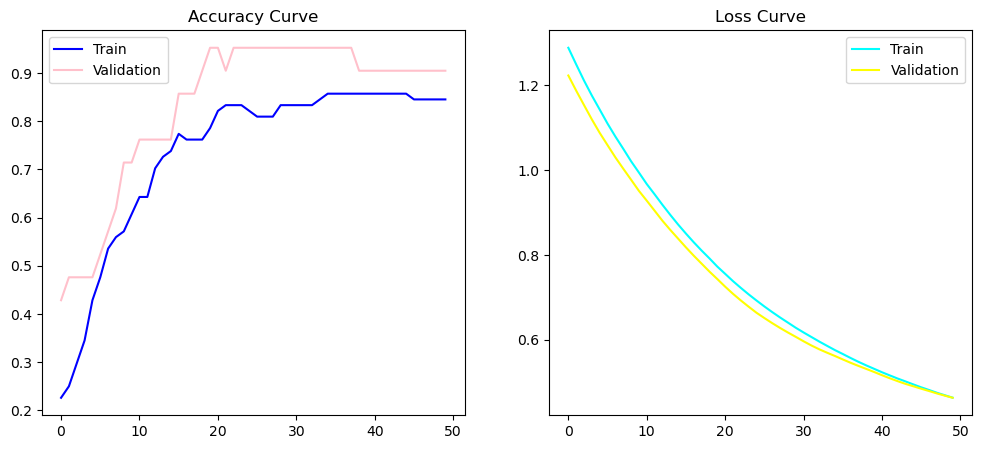

In [12]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label="Train", color="blue")
plt.plot(history.history['val_accuracy'], label="Validation", color="pink")
plt.title("Accuracy Curve")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label="Train", color="cyan")
plt.plot(history.history['val_loss'], label="Validation", color="yellow")
plt.title("Loss Curve")
plt.legend()

plt.show()